# Module 2.4 — Visual Exploratory Data Analysis

## Exploring fictional appointment data with Matplotlib and Seaborn

A chart should help answer a question—not simply decorate a notebook. In this lesson, we will select appropriate chart types, build them with Matplotlib and Seaborn, and interpret what they show without overstating the evidence.

> **Privacy note:** Every appointment in this notebook is fictional. The values are designed for learning and do not describe any real clinic, patient, or service.

## Learning objectives

By the end of this notebook, you will be able to:

- Match chart types to analytical questions and variable types.
- Use Matplotlib's figure–axes pattern.
- Create readable bar charts for categorical counts.
- Explore numerical distributions with histograms, box plots, and individual points.
- Compare distributions across groups.
- Use scatter plots to examine relationships between two numerical variables.
- Build time-series line charts from correctly aggregated data.
- Create multi-panel figures with shared visual conventions.
- Improve titles, labels, legends, scales, and layout.
- Identify misleading design choices and distinguish observation from explanation.
- Save a figure reproducibly.

## Lesson roadmap

| Part | Focus |
|---|---|
| 1 | Prepare and inspect the fictional data |
| 2 | Learn the figure–axes pattern |
| 3 | Visualise categories and distributions |
| 4 | Compare groups and relationships |
| 5 | Visualise time-based summaries |
| 6 | Build and critique a small visual report |
| 7 | Practice and test your knowledge |

**Working pattern:** question → variable types → chart choice → data preparation → chart → validation → interpretation.

## 1. Setup

This notebook uses pandas, Matplotlib, and Seaborn. If an import fails, install the libraries in the same environment used by the notebook:

```text
python -m pip install pandas matplotlib seaborn
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

print("pandas:", pd.__version__)
print("seaborn:", sns.__version__)

pandas: 2.2.3
seaborn: 0.13.2


## 2. Create the fictional administrative dataset

Each row represents one appointment. We include enough variation to practise categorical, numerical, relational, and time-based visualisation.

The data is deliberately fictional. Any pattern you see is an artefact of this teaching dataset.

In [2]:
records = [
    ["APT-3001", "2026-09-01", "General Practice", "Initial",   "Completed", 12, 20, 5, True,  "Phone"],
    ["APT-3002", "2026-09-01", "Physiotherapy",   "Follow-up", "Completed", 25, 30, 7, True,  "Online"],
    ["APT-3003", "2026-09-01", "Dermatology",     "Initial",   "Completed",  8, 20, 3, False, "Phone"],
    ["APT-3004", "2026-09-02", "General Practice", "Follow-up", "Cancelled", pd.NA, 15, 4, True, "Online"],
    ["APT-3005", "2026-09-02", "Physiotherapy",   "Initial",   "Completed", 40, 45, 8, True,  "Reception"],
    ["APT-3006", "2026-09-02", "General Practice", "Initial",   "Missed",   pd.NA, 20, 2, False, "Phone"],
    ["APT-3007", "2026-09-03", "Dermatology",     "Follow-up", "Completed", 18, 15, 6, True,  "Online"],
    ["APT-3008", "2026-09-03", "General Practice", "Initial",   "Completed",  6, 20, 3, True,  "Reception"],
    ["APT-3009", "2026-09-03", "Physiotherapy",   "Follow-up", "Completed", 22, 30, 5, True,  "Online"],
    ["APT-3010", "2026-09-04", "Dermatology",     "Initial",   "Cancelled", pd.NA, 20, 6, False, "Phone"],
    ["APT-3011", "2026-09-04", "General Practice", "Follow-up", "Completed", 10, 15, 2, True,  "Online"],
    ["APT-3012", "2026-09-04", "Physiotherapy",   "Initial",   "Missed",   pd.NA, 45, 9, True,  "Reception"],
    ["APT-3013", "2026-09-05", "Dermatology",     "Initial",   "Completed", 14, 20, 4, True,  "Online"],
    ["APT-3014", "2026-09-05", "General Practice", "Follow-up", "Completed", 16, 15, 3, False, "Phone"],
    ["APT-3015", "2026-09-05", "Physiotherapy",   "Initial",   "Cancelled", pd.NA, 45, 6, True, "Online"],
    ["APT-3016", "2026-09-06", "Dermatology",     "Follow-up", "Missed",   pd.NA, 15, 8, False, "Reception"],
    ["APT-3017", "2026-09-06", "General Practice", "Initial",   "Completed",  9, 20, 5, True,  "Online"],
    ["APT-3018", "2026-09-06", "Physiotherapy",   "Follow-up", "Completed", 28, 30, 4, True,  "Phone"],
    ["APT-3019", "2026-09-07", "Dermatology",     "Initial",   "Completed", 11, 20, 2, True,  "Reception"],
    ["APT-3020", "2026-09-07", "General Practice", "Initial",   "Completed", 17, 25, 7, True,  "Online"],
    ["APT-3021", "2026-09-07", "Physiotherapy",   "Initial",   "Completed", 35, 45, 10, True, "Online"],
    ["APT-3022", "2026-09-08", "Dermatology",     "Follow-up", "Completed", 20, 15, 5, False, "Phone"],
    ["APT-3023", "2026-09-08", "General Practice", "Follow-up", "Cancelled", pd.NA, 15, 1, True, "Reception"],
    ["APT-3024", "2026-09-08", "Physiotherapy",   "Follow-up", "Completed", 31, 30, 7, True, "Online"],
    ["APT-3025", "2026-09-09", "Dermatology",     "Initial",   "Completed", 13, 20, 3, True, "Online"],
    ["APT-3026", "2026-09-09", "General Practice", "Initial",   "Missed",   pd.NA, 20, 6, False, "Phone"],
    ["APT-3027", "2026-09-09", "Physiotherapy",   "Initial",   "Completed", 38, 45, 9, True, "Reception"],
    ["APT-3028", "2026-09-10", "Dermatology",     "Follow-up", "Cancelled", pd.NA, 15, 4, True, "Online"],
    ["APT-3029", "2026-09-10", "General Practice", "Follow-up", "Completed",  7, 15, 2, True, "Online"],
    ["APT-3030", "2026-09-10", "Physiotherapy",   "Follow-up", "Missed",   pd.NA, 30, 5, False, "Phone"],
    ["APT-3031", "2026-09-11", "Dermatology",     "Initial",   "Completed", 15, 20, 6, True, "Reception"],
    ["APT-3032", "2026-09-11", "General Practice", "Initial",   "Completed", 11, 20, 4, True, "Online"],
    ["APT-3033", "2026-09-11", "Physiotherapy",   "Initial",   "Completed", 45, 45, 11, True, "Online"],
    ["APT-3034", "2026-09-12", "Dermatology",     "Follow-up", "Completed", 19, 15, 3, False, "Phone"],
    ["APT-3035", "2026-09-12", "General Practice", "Follow-up", "Completed", 14, 15, 8, True, "Reception"],
    ["APT-3036", "2026-09-12", "Physiotherapy",   "Follow-up", "Cancelled", pd.NA, 30, 6, True, "Online"],
]

columns = [
    "appointment_id", "appointment_date", "department", "appointment_type",
    "status", "wait_minutes", "scheduled_minutes", "lead_days",
    "reminder_sent", "booking_channel"
]

appointments_df = pd.DataFrame(records, columns=columns)
appointments_df["appointment_date"] = pd.to_datetime(appointments_df["appointment_date"])
appointments_df["wait_minutes"] = appointments_df["wait_minutes"].astype("Int64")
appointments_df["scheduled_minutes"] = appointments_df["scheduled_minutes"].astype("Int64")
appointments_df.head()

,appointment_id,appointment_date,department,appointment_type,status,wait_minutes,scheduled_minutes,lead_days,reminder_sent,booking_channel
0,APT-3001,2026-09-01,General Practice,Initial,Completed,12,20,5,True,Phone
1,APT-3002,2026-09-01,Physiotherapy,Follow-up,Completed,25,30,7,True,Online
2,APT-3003,2026-09-01,Dermatology,Initial,Completed,8,20,3,False,Phone
3,APT-3004,2026-09-02,General Practice,Follow-up,Cancelled,<NA>,15,4,True,Online
4,APT-3005,2026-09-02,Physiotherapy,Initial,Completed,40,45,8,True,Reception


### Inspect before plotting

A graph cannot repair an incorrect schema. Check dimensions, data types, missingness, categories, and plausible numerical ranges first.

In [3]:
print("Shape:", appointments_df.shape)
print("\nMissing values:")
print(appointments_df.isna().sum())
print("\nStatuses:", appointments_df["status"].unique().tolist())
print("Departments:", appointments_df["department"].unique().tolist())
print("\nNumerical summary:")
display(appointments_df[["wait_minutes", "scheduled_minutes", "lead_days"]].describe())

Shape: (36, 10)

Missing values:
appointment_id        0
appointment_date      0
department            0
appointment_type      0
status                0
wait_minutes         11
scheduled_minutes     0
lead_days             0
reminder_sent         0
booking_channel       0
dtype: int64

Statuses: ['Completed', 'Cancelled', 'Missed']
Departments: ['General Practice', 'Physiotherapy', 'Dermatology']

Numerical summary:


,wait_minutes,scheduled_minutes,lead_days
count,25.0,36.0,36.000000
mean,19.36,24.444444,5.250000
std,11.010904,10.608472,2.465476
min,6.0,15.0,1.000000
25%,11.0,15.0,3.000000
50%,16.0,20.0,5.000000
75%,25.0,30.0,7.000000
max,45.0,45.0,11.000000


## 3. Choose the chart from the question

| Question | Variables | Useful starting chart |
|---|---|---|
| How many appointments belong to each status? | One categorical | Bar chart |
| What is the distribution of waiting time? | One numerical | Histogram and box plot |
| How does waiting time differ by department? | Numerical + categorical | Box plot with points |
| Are lead time and waiting time associated? | Two numerical | Scatter plot |
| How does daily appointment count change? | Date + aggregated numerical | Line chart |
| How do status proportions vary by department? | Two categorical | 100% stacked bar or heatmap |

A chart type should match the variables and the question. Start with the simplest view that can answer it.

## 4. The figure–axes pattern

Matplotlib separates the whole **figure** from one or more **axes**. The axes is the plotting area where data, labels, and annotations are placed.

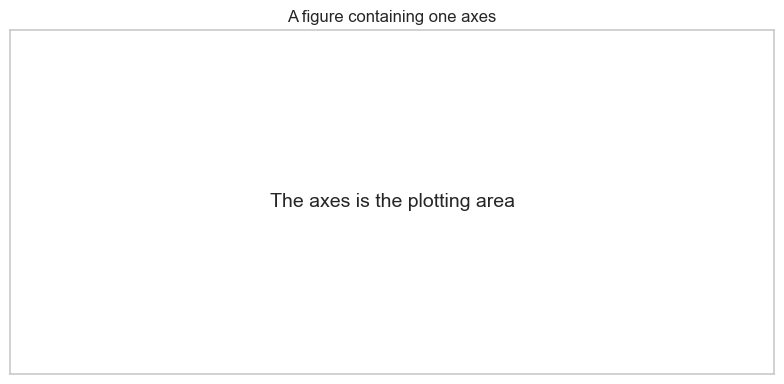

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.text(
    0.5, 0.5,
    "The axes is the plotting area",
    ha="center", va="center", fontsize=14
)
ax.set_title("A figure containing one axes")
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.show()

> Using `fig, ax = plt.subplots()` makes it clear which chart object you are modifying. This becomes especially useful when a figure contains several panels.

## 5. Bar chart for categorical counts

A bar chart compares values across discrete categories. Calculate the counts first so the plotted numbers are visible and testable.

In [5]:
status_counts = (
    appointments_df["status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="appointment_count")
)

status_counts

,status,appointment_count
0,Completed,25
1,Cancelled,6
2,Missed,5


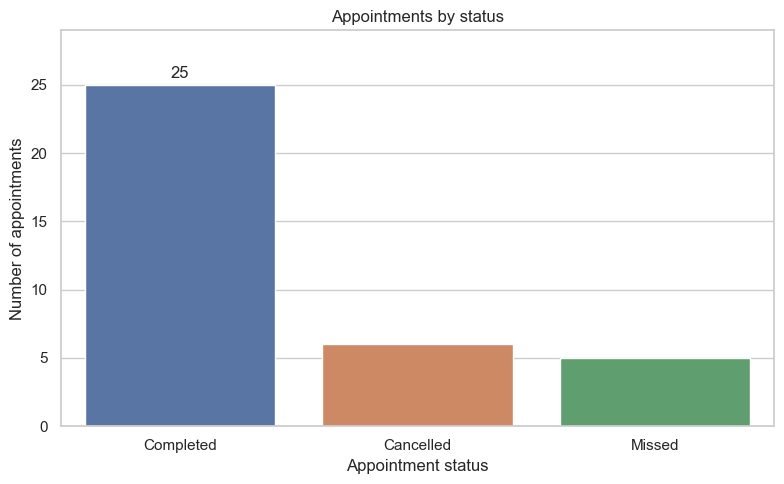

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=status_counts,
    x="status",
    y="appointment_count",
    hue="status",
    legend=False,
    ax=ax,
)

ax.set_title("Appointments by status")
ax.set_xlabel("Appointment status")
ax.set_ylabel("Number of appointments")
ax.bar_label(ax.containers[0], padding=3)
ax.set_ylim(0, status_counts["appointment_count"].max() + 4)

plt.tight_layout()
plt.show()

### Interpret carefully

**Observation:** Completed is the most common status in this fictional extract.

**Not supported:** The chart does not show why appointments were cancelled or missed, whether the period is representative, or whether one status causes another outcome.

## 6. Order categories intentionally

Alphabetical order is not always useful. Sorting bars by value can make ranking easier to read. Horizontal bars also help when labels are long.

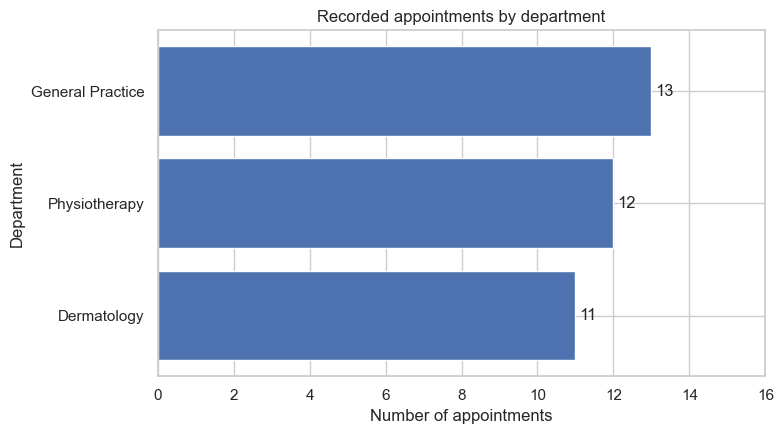

In [7]:
department_counts = (
    appointments_df["department"]
    .value_counts()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(department_counts.index, department_counts.values)
ax.set_title("Recorded appointments by department")
ax.set_xlabel("Number of appointments")
ax.set_ylabel("Department")
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlim(0, department_counts.max() + 3)

plt.tight_layout()
plt.show()

> A bar chart usually needs a zero baseline because length encodes value. Truncating the value axis can exaggerate small differences.

## 7. Histogram for a numerical distribution

A histogram groups numerical observations into intervals called bins. Here we use only recorded waiting times.

In [8]:
recorded_waits = appointments_df.loc[
    appointments_df["wait_minutes"].notna(), "wait_minutes"
].astype(float)

print("Recorded waits:", len(recorded_waits))
print("Missing waits:", appointments_df["wait_minutes"].isna().sum())

Recorded waits: 25
Missing waits: 11


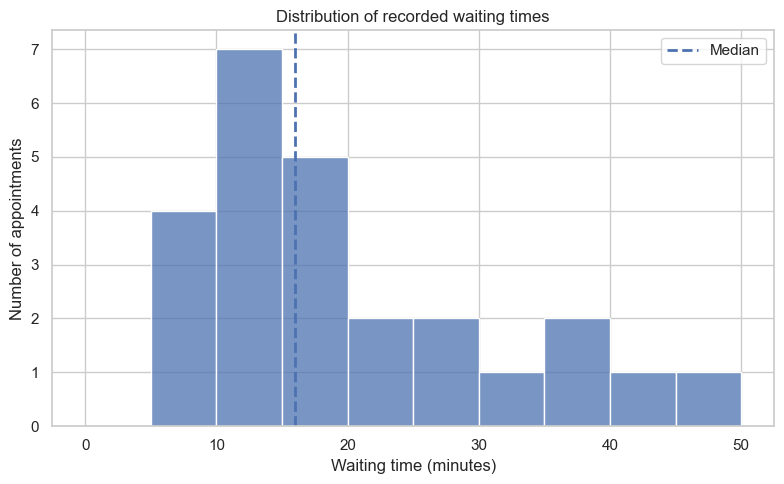

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    recorded_waits,
    bins=range(0, 51, 5),
    edgecolor="white",
    ax=ax,
)

ax.axvline(recorded_waits.median(), linestyle="--", linewidth=2, label="Median")
ax.set_title("Distribution of recorded waiting times")
ax.set_xlabel("Waiting time (minutes)")
ax.set_ylabel("Number of appointments")
ax.legend()

plt.tight_layout()
plt.show()

### Bins affect the view

Changing the bin width can reveal or hide structure. Compare several sensible choices rather than treating the default as objectively correct.

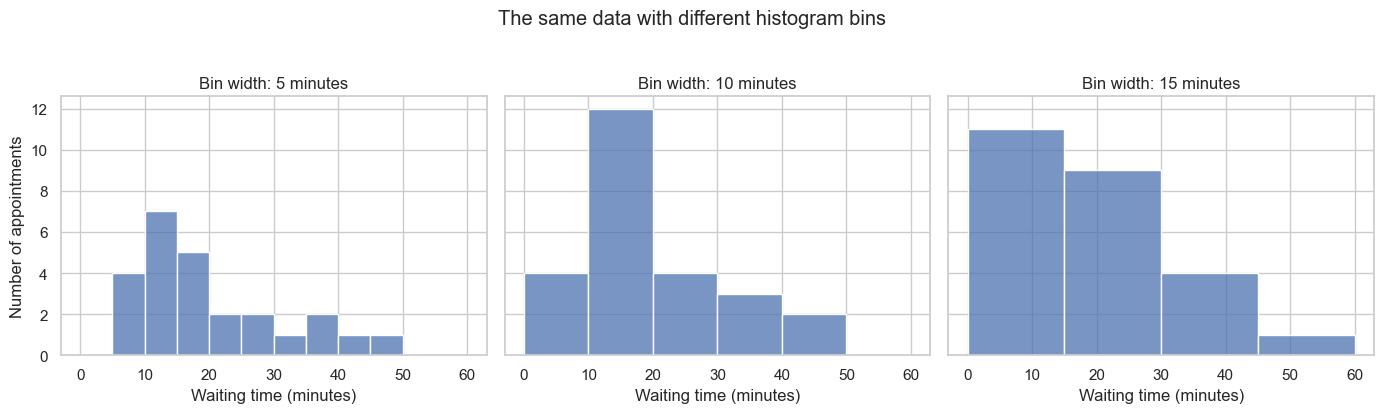

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, bin_width in zip(axes, [5, 10, 15]):
    bins = range(0, 61, bin_width)
    sns.histplot(recorded_waits, bins=bins, edgecolor="white", ax=ax)
    ax.set_title(f"Bin width: {bin_width} minutes")
    ax.set_xlabel("Waiting time (minutes)")

axes[0].set_ylabel("Number of appointments")
fig.suptitle("The same data with different histogram bins", y=1.03)

plt.tight_layout()
plt.show()

> A histogram summarises recorded values; it does not show cancelled or missed appointments whose waiting time is missing. State that scope when interpreting the chart.

## 8. Box plot for a compact summary

A box plot displays the median, quartiles, whiskers, and potential outlying points. A point beyond a whisker is not automatically an error; it is a value to investigate.

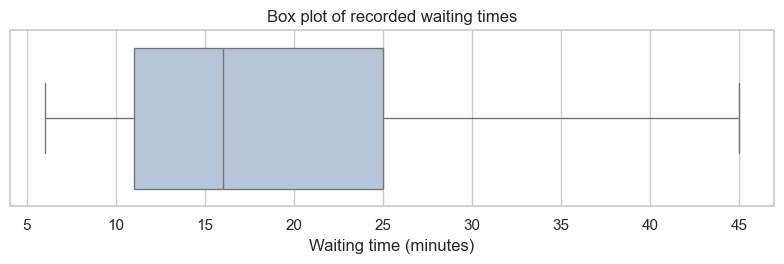

In [11]:
fig, ax = plt.subplots(figsize=(8, 2.8))

sns.boxplot(
    data=appointments_df,
    x="wait_minutes",
    color="lightsteelblue",
    ax=ax,
)

ax.set_title("Box plot of recorded waiting times")
ax.set_xlabel("Waiting time (minutes)")

plt.tight_layout()
plt.show()

### Read a box plot

- The line inside the box is the median.
- The box spans the first to third quartiles.
- Its width along the numerical axis is the interquartile range.
- Whiskers commonly extend to observed values within 1.5 interquartile ranges of the box.
- Values beyond the whiskers are plotted separately and should be examined in context.

## 9. Compare distributions by department

A grouped box plot shows compact summaries, but our dataset is small. Overlaying individual observations prevents the summary from hiding how few values are present.

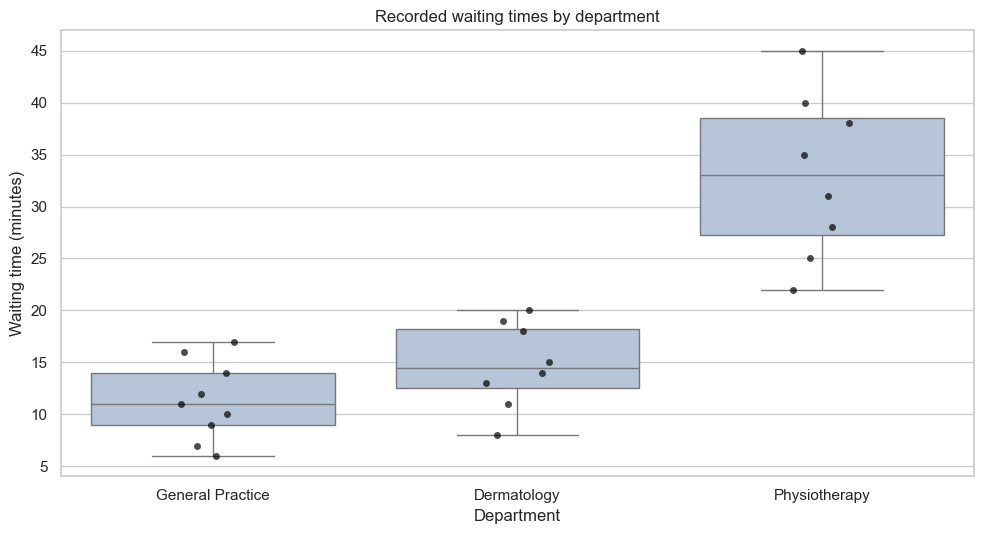

In [12]:
department_order = ["General Practice", "Dermatology", "Physiotherapy"]

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.boxplot(
    data=appointments_df,
    x="department",
    y="wait_minutes",
    order=department_order,
    showfliers=False,
    color="lightsteelblue",
    ax=ax,
)

sns.stripplot(
    data=appointments_df,
    x="department",
    y="wait_minutes",
    order=department_order,
    color="black",
    alpha=0.7,
    jitter=0.12,
    size=5,
    ax=ax,
)

ax.set_title("Recorded waiting times by department")
ax.set_xlabel("Department")
ax.set_ylabel("Waiting time (minutes)")

plt.tight_layout()
plt.show()

**Observation:** In this fictional extract, the recorded Physiotherapy waits generally appear higher than the other groups.

**Not supported:** The graph does not establish a department effect. Appointment type, scheduling, missingness, sample size, and the artificial data-generation choices could all matter.

## 10. Compare appointment types

A violin plot estimates a smooth distribution shape. With a small sample, that smooth shape may imply more precision than the data supports, so we add individual points.

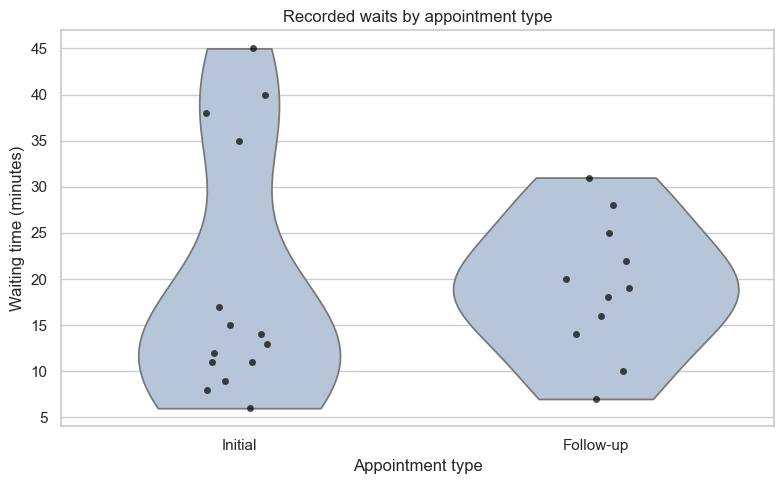

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.violinplot(
    data=appointments_df,
    x="appointment_type",
    y="wait_minutes",
    inner=None,
    cut=0,
    color="lightsteelblue",
    ax=ax,
)
sns.stripplot(
    data=appointments_df,
    x="appointment_type",
    y="wait_minutes",
    color="black",
    alpha=0.7,
    jitter=0.1,
    ax=ax,
)

ax.set_title("Recorded waits by appointment type")
ax.set_xlabel("Appointment type")
ax.set_ylabel("Waiting time (minutes)")

plt.tight_layout()
plt.show()

> Smooth density shapes are estimates, not raw observations. For small groups, always consider showing the points or using a simpler box plot.

## 11. Scatter plot for two numerical variables

A scatter plot places one observation at each pair of numerical values. We will compare booking lead time with recorded waiting time.

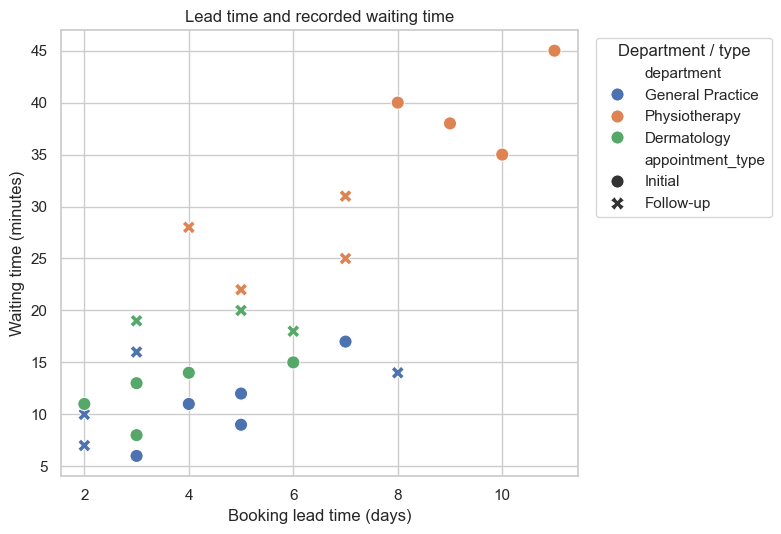

In [14]:
scatter_df = appointments_df.dropna(subset=["lead_days", "wait_minutes"]).copy()

fig, ax = plt.subplots(figsize=(8, 5.5))

sns.scatterplot(
    data=scatter_df,
    x="lead_days",
    y="wait_minutes",
    hue="department",
    style="appointment_type",
    s=90,
    ax=ax,
)

ax.set_title("Lead time and recorded waiting time")
ax.set_xlabel("Booking lead time (days)")
ax.set_ylabel("Waiting time (minutes)")
ax.legend(title="Department / type", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

### Questions to ask of a scatter plot

- Is the form roughly linear, curved, clustered, or patternless?
- Is the direction positive, negative, or unclear?
- How strong is the visual relationship?
- Are there unusual points?
- Do groups occupy different regions?
- Could a third variable explain the pattern?

A visible association does not prove that one variable causes the other.

## 12. Add a fitted trend cautiously

A fitted line can summarise a linear pattern, but it should not be interpreted as causal. The shaded interval reflects uncertainty in the fitted mean under the model assumptions—not the range of future observations.

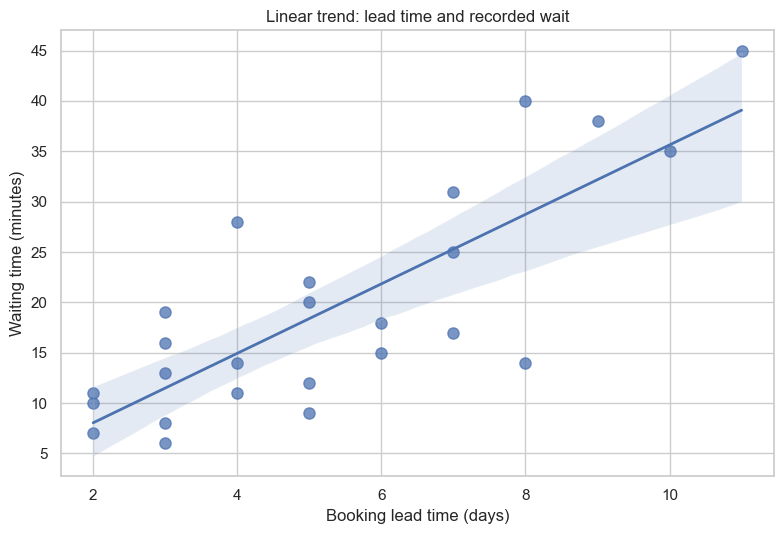

In [15]:
fig, ax = plt.subplots(figsize=(8, 5.5))

sns.regplot(
    data=scatter_df,
    x="lead_days",
    y="wait_minutes",
    scatter_kws={"alpha": 0.75, "s": 65},
    line_kws={"linewidth": 2},
    ax=ax,
)

ax.set_title("Linear trend: lead time and recorded wait")
ax.set_xlabel("Booking lead time (days)")
ax.set_ylabel("Waiting time (minutes)")

plt.tight_layout()
plt.show()

> The points show observations; the line is a model-based summary. Always inspect the points before relying on a fitted line.

## 13. Time series require aggregation

A line chart is appropriate for an ordered sequence such as dates. First calculate one value for each date; do not connect individual appointments merely because they appear in row order.

In [16]:
daily_summary = (
    appointments_df
    .groupby("appointment_date", as_index=False)
    .agg(
        appointment_count=("appointment_id", "size"),
        completed_count=("status", lambda values: (values == "Completed").sum()),
        recorded_wait_count=("wait_minutes", "count"),
        mean_wait_minutes=("wait_minutes", "mean"),
    )
)

daily_summary["mean_wait_minutes"] = daily_summary["mean_wait_minutes"].round(1)
daily_summary.head()

,appointment_date,appointment_count,completed_count,recorded_wait_count,mean_wait_minutes
0,2026-09-01,3,3,3,15.0
1,2026-09-02,3,1,1,40.0
2,2026-09-03,3,3,3,15.3
3,2026-09-04,3,1,1,10.0
4,2026-09-05,3,2,2,15.0


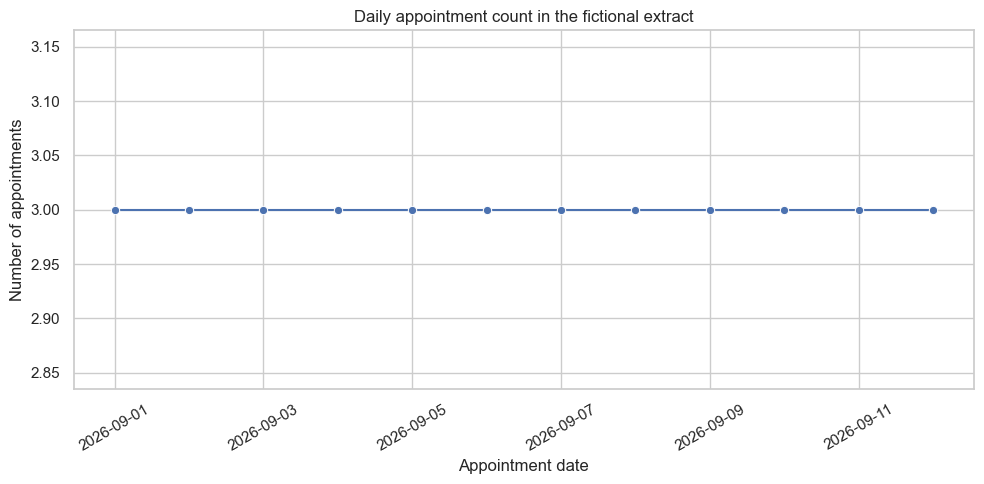

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=daily_summary,
    x="appointment_date",
    y="appointment_count",
    marker="o",
    ax=ax,
)

ax.set_title("Daily appointment count in the fictional extract")
ax.set_xlabel("Appointment date")
ax.set_ylabel("Number of appointments")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

> The dates form an ordered axis, but twelve days is too short to support claims about long-term trends or seasonality.

## 14. Small multiples

Small multiples repeat the same chart structure for different groups. Shared axes make visual comparison easier.

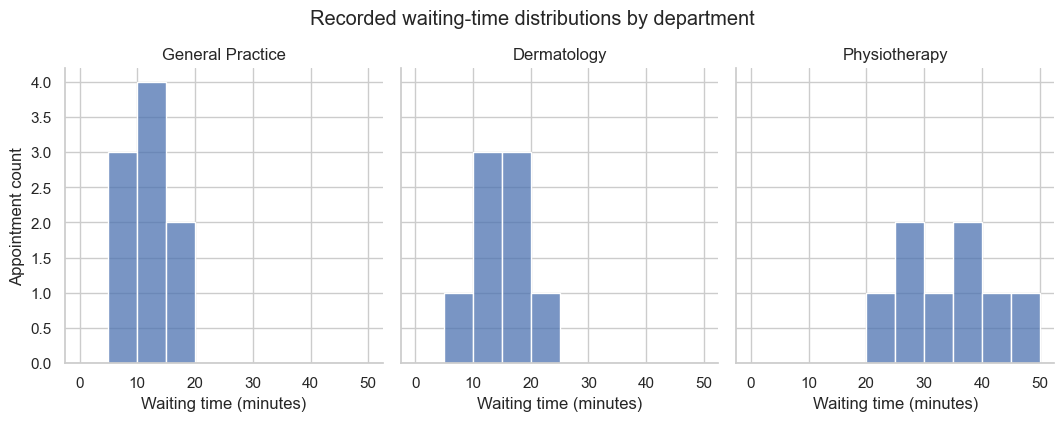

In [18]:
g = sns.displot(
    data=appointments_df,
    x="wait_minutes",
    col="department",
    col_order=department_order,
    bins=range(0, 51, 5),
    height=4,
    aspect=0.9,
    edgecolor="white",
)

g.set_axis_labels("Waiting time (minutes)", "Appointment count")
g.set_titles("{col_name}")
g.figure.suptitle("Recorded waiting-time distributions by department", y=1.05)

plt.show()

### When to use small multiples

Small multiples can be clearer than placing several overlapping distributions in one panel. They need consistent scales and the same bin definitions so viewers can compare like with like.

## 15. Two categorical variables

A 100% stacked bar chart can compare the composition of statuses within each department. First compute counts, then divide each row by its own total.

In [19]:
status_by_department = pd.crosstab(
    appointments_df["department"],
    appointments_df["status"],
)

status_percent = status_by_department.div(
    status_by_department.sum(axis=1),
    axis=0,
).mul(100)

status_percent

status,Cancelled,Completed,Missed
department,,,
Dermatology,18.181818,72.727273,9.090909
General Practice,15.384615,69.230769,15.384615
Physiotherapy,16.666667,66.666667,16.666667


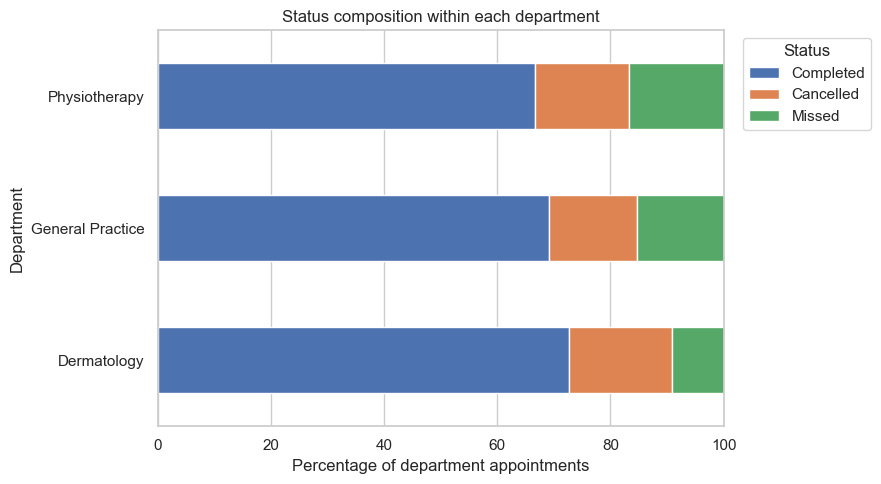

In [20]:
ordered_statuses = ["Completed", "Cancelled", "Missed"]
status_percent = status_percent.reindex(columns=ordered_statuses, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 5))

status_percent.plot(
    kind="barh",
    stacked=True,
    ax=ax,
)

ax.set_title("Status composition within each department")
ax.set_xlabel("Percentage of department appointments")
ax.set_ylabel("Department")
ax.set_xlim(0, 100)
ax.legend(title="Status", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

> Every bar totals 100%, so this chart compares composition rather than total volume. A department with fewer records can occupy the same bar length as a department with more records; report counts nearby.

## 16. Heatmap for a numerical matrix

A heatmap encodes table values with colour. It works best when the matrix is not too large and the colour scale has a clear meaning.

In [21]:
wait_matrix = appointments_df.pivot_table(
    values="wait_minutes",
    index="department",
    columns="appointment_type",
    aggfunc="median",
)

wait_matrix = wait_matrix.astype(float)
wait_matrix

appointment_type,Follow-up,Initial
department,,
Dermatology,19.0,13.0
General Practice,12.0,11.0
Physiotherapy,26.5,39.0


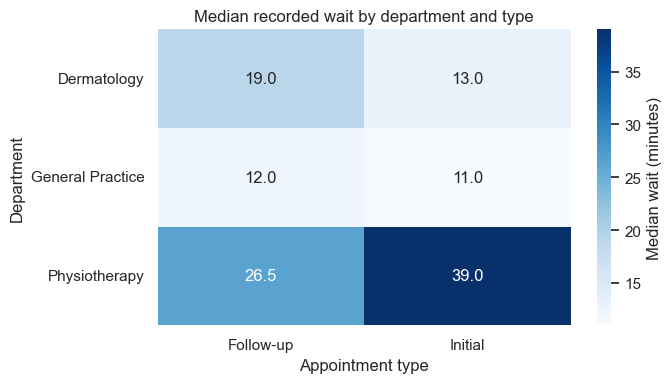

In [22]:
fig, ax = plt.subplots(figsize=(7, 4))

sns.heatmap(
    wait_matrix,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    cbar_kws={"label": "Median wait (minutes)"},
    ax=ax,
)

ax.set_title("Median recorded wait by department and type")
ax.set_xlabel("Appointment type")
ax.set_ylabel("Department")

plt.tight_layout()
plt.show()

> A heatmap can make differences easy to scan, but colour should not replace displayed values when exact interpretation matters. Also verify how many records contribute to each cell.

In [23]:
wait_cell_counts = appointments_df.pivot_table(
    values="wait_minutes",
    index="department",
    columns="appointment_type",
    aggfunc="count",
)

wait_cell_counts

appointment_type,Follow-up,Initial
department,,
Dermatology,3,5
General Practice,4,5
Physiotherapy,4,4


## 17. Build a multi-panel visual report

A coordinated figure can answer related questions while keeping styles consistent. Each panel still needs a clear purpose.

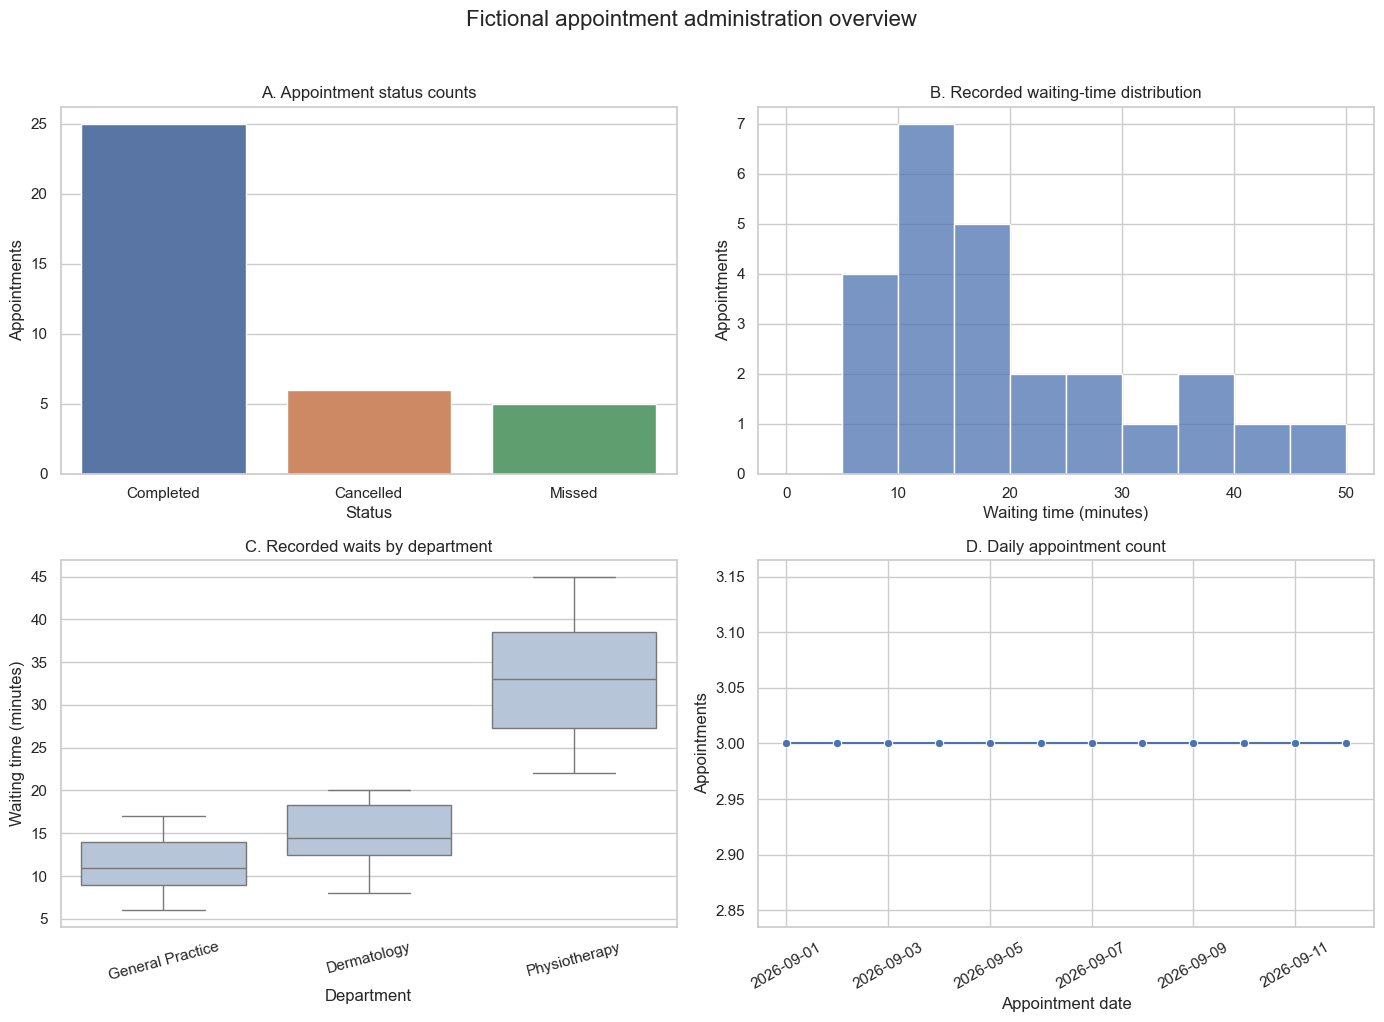

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: status counts
sns.barplot(
    data=status_counts,
    x="status",
    y="appointment_count",
    hue="status",
    legend=False,
    ax=axes[0, 0],
)
axes[0, 0].set_title("A. Appointment status counts")
axes[0, 0].set_xlabel("Status")
axes[0, 0].set_ylabel("Appointments")

# Panel 2: waiting-time distribution
sns.histplot(
    recorded_waits,
    bins=range(0, 51, 5),
    edgecolor="white",
    ax=axes[0, 1],
)
axes[0, 1].set_title("B. Recorded waiting-time distribution")
axes[0, 1].set_xlabel("Waiting time (minutes)")
axes[0, 1].set_ylabel("Appointments")

# Panel 3: waits by department
sns.boxplot(
    data=appointments_df,
    x="department",
    y="wait_minutes",
    order=department_order,
    color="lightsteelblue",
    ax=axes[1, 0],
)
axes[1, 0].set_title("C. Recorded waits by department")
axes[1, 0].set_xlabel("Department")
axes[1, 0].set_ylabel("Waiting time (minutes)")
axes[1, 0].tick_params(axis="x", rotation=15)

# Panel 4: daily counts
sns.lineplot(
    data=daily_summary,
    x="appointment_date",
    y="appointment_count",
    marker="o",
    ax=axes[1, 1],
)
axes[1, 1].set_title("D. Daily appointment count")
axes[1, 1].set_xlabel("Appointment date")
axes[1, 1].set_ylabel("Appointments")
axes[1, 1].tick_params(axis="x", rotation=30)

fig.suptitle("Fictional appointment administration overview", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Read the report in layers

- Panel A gives categorical volume.
- Panel B shows the shape of recorded waits.
- Panel C compares group distributions.
- Panel D shows the short sequence of daily counts.

The panels describe different aspects of the extract; none explains the cause of a pattern.

## 18. Avoid misleading charts

### Truncated bar axes

The two panels below contain the same department counts. The right-hand chart truncates the axis, visually exaggerating a small difference.

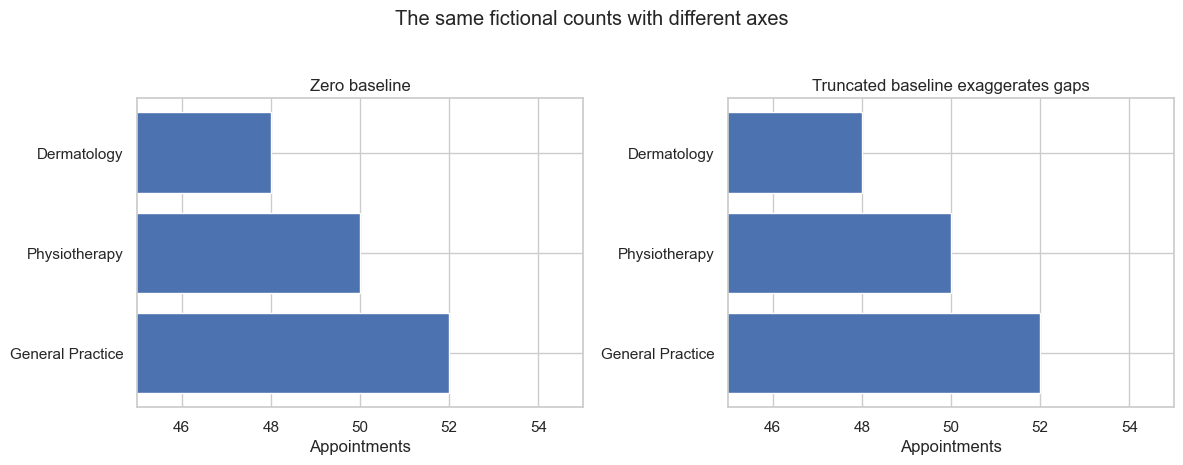

In [25]:
demo_counts = pd.Series(
    {"General Practice": 52, "Physiotherapy": 50, "Dermatology": 48}
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)

axes[0].barh(demo_counts.index, demo_counts.values)
axes[0].set_xlim(0, 55)
axes[0].set_title("Zero baseline")
axes[0].set_xlabel("Appointments")

axes[1].barh(demo_counts.index, demo_counts.values)
axes[1].set_xlim(45, 55)
axes[1].set_title("Truncated baseline exaggerates gaps")
axes[1].set_xlabel("Appointments")

fig.suptitle("The same fictional counts with different axes", y=1.03)
plt.tight_layout()
plt.show()

### Design checklist

- Start bar-chart value axes at zero unless a strong reason is clearly disclosed.
- Label axes with units.
- Use titles that state what is measured.
- Sort categories deliberately.
- Avoid unnecessary 3D effects and visual decoration.
- Use colour consistently and sparingly.
- Do not use a line chart for unordered categories.
- Show sample counts when group sizes matter.
- Do not hide missing values without explanation.
- Keep scales consistent across comparable panels.

## 19. Save a figure reproducibly

Save the figure before `plt.show()` so the complete object is available. `bbox_inches="tight"` includes labels and legends that extend beyond the default canvas.

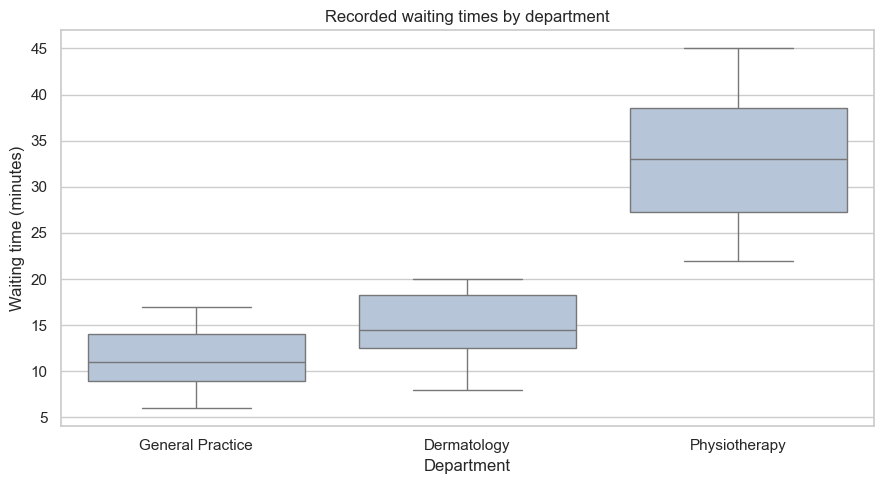

Saved: fictional_waits_by_department.png
File exists: True


In [26]:
figure_path = Path("fictional_waits_by_department.png")

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    data=appointments_df,
    x="department",
    y="wait_minutes",
    order=department_order,
    color="lightsteelblue",
    ax=ax,
)
ax.set_title("Recorded waiting times by department")
ax.set_xlabel("Department")
ax.set_ylabel("Waiting time (minutes)")

plt.tight_layout()
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", figure_path)
print("File exists:", figure_path.exists())

## 20. Reusable plotting function

A function can enforce consistent titles, labels, category order, and validation.

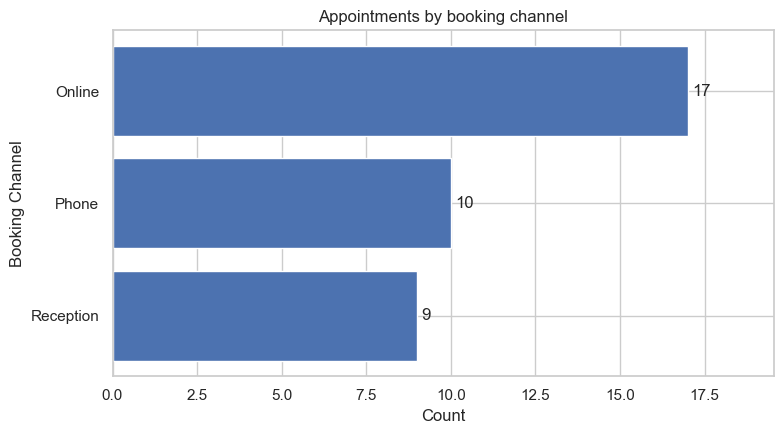

In [27]:
def plot_category_counts(df, column, title, x_label="Count"):
    """Plot sorted counts for one categorical column."""
    if column not in df.columns:
        raise KeyError(f"Column not found: {column}")

    counts = df[column].value_counts(dropna=False).sort_values()

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.barh(counts.index.astype(str), counts.values)
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(column.replace("_", " ").title())
    ax.bar_label(ax.containers[0], padding=3)
    ax.set_xlim(0, counts.max() + max(1, counts.max() * 0.15))
    plt.tight_layout()
    return fig, ax


fig, ax = plot_category_counts(
    appointments_df,
    "booking_channel",
    "Appointments by booking channel",
)
plt.show()

## 21. Code-along challenge

Create one figure with two panels:

- **Left:** Count of appointments by booking channel, ordered from highest to lowest.
- **Right:** Recorded waiting-time box plots by booking channel with individual points overlaid.

Requirements:

1. Use `fig, axes = plt.subplots(...)`.
2. Give each panel a specific title.
3. Label every axis with a meaningful name and units where relevant.
4. Use the same booking-channel order in both panels.
5. Add one observation and one limitation in Markdown.

In [28]:
# Build your two-panel figure here.

<details>
<summary><strong>Reveal one possible solution</strong></summary>

Run the next cell after attempting the challenge.
</details>

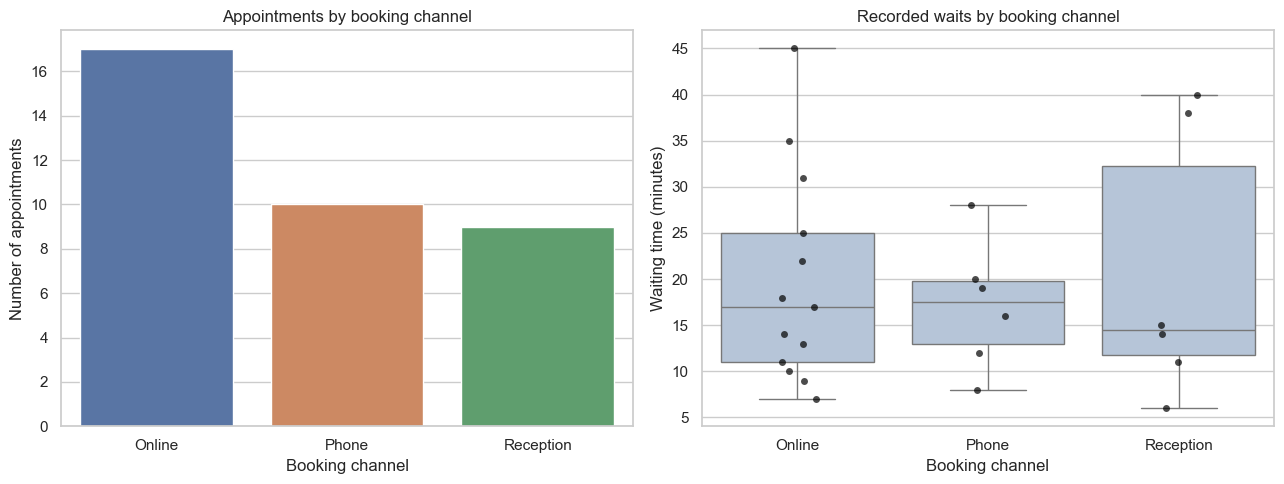

In [29]:
channel_order = appointments_df["booking_channel"].value_counts().index.tolist()
channel_counts = (
    appointments_df["booking_channel"]
    .value_counts()
    .reindex(channel_order)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    x=channel_counts.index,
    y=channel_counts.values,
    hue=channel_counts.index,
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Appointments by booking channel")
axes[0].set_xlabel("Booking channel")
axes[0].set_ylabel("Number of appointments")

sns.boxplot(
    data=appointments_df,
    x="booking_channel",
    y="wait_minutes",
    order=channel_order,
    showfliers=False,
    color="lightsteelblue",
    ax=axes[1],
)
sns.stripplot(
    data=appointments_df,
    x="booking_channel",
    y="wait_minutes",
    order=channel_order,
    color="black",
    alpha=0.7,
    jitter=0.1,
    ax=axes[1],
)
axes[1].set_title("Recorded waits by booking channel")
axes[1].set_xlabel("Booking channel")
axes[1].set_ylabel("Waiting time (minutes)")

plt.tight_layout()
plt.show()

**Example observation:** Online is the most frequent booking channel in the fictional extract.

**Example limitation:** The chart does not show whether booking channel affects waiting time because channel use may differ by department, appointment type, date, or other variables.

## 22. Independent practice

Use `appointments_df` to create and interpret the following charts:

1. A bar chart of appointment type counts.
2. A histogram of booking lead days using justified bins.
3. A box plot of lead days by status with individual points.
4. A scatter plot of scheduled minutes against waiting time, coloured by department.
5. A daily line chart showing completed and total appointments.
6. A heatmap of status counts by department.

For every chart, include:

- A question.
- A descriptive title.
- Labelled axes and units.
- The exact subset used.
- One evidence-based observation.
- One limitation or alternative explanation.

In [30]:
# Write your independent-practice visual analysis here.

## 23. Visual review checklist

Before sharing a chart, ask:

- Does this chart answer the stated question?
- Are the variables appropriate for this chart type?
- Did I aggregate at the correct level?
- Are missing values excluded, included, or labelled deliberately?
- Are categories ordered meaningfully?
- Are both axes labelled with units?
- Is the title specific rather than generic?
- Does the scale distort the comparison?
- Are colours consistent and distinguishable?
- Is every legend necessary and correctly titled?
- Are group counts visible or available?
- Does my interpretation describe rather than speculate?

## 24. Test your knowledge!

Answer without running new code first.

1. What is the difference between a Matplotlib figure and axes?
2. Which chart is a useful starting point for counts of one categorical variable?
3. Why should a bar chart's value axis usually begin at zero?
4. What does a histogram bin represent?
5. Why should you compare more than one reasonable bin width?
6. What do the box and centre line in a box plot represent?
7. Does a point beyond a box-plot whisker prove that the value is incorrect?
8. Why overlay individual points on a box or violin plot for a small dataset?
9. Which chart is suitable for two numerical variables?
10. What does a fitted line add to a scatter plot, and what does it not prove?
11. Why must appointment-level rows be aggregated before a daily line chart?
12. What is the denominator in a 100% stacked department bar?
13. Why should counts accompany percentages?
14. How can inconsistent scales undermine small-multiple comparisons?
15. What is the difference between an observation and an explanation?

<details>
<summary><strong>Check your answers</strong></summary>

1. A figure is the full canvas; axes is an individual plotting area within it.
2. A bar chart.
3. Bar length encodes magnitude, and a truncated baseline can exaggerate differences.
4. A numerical interval and the observations counted within it.
5. Apparent distribution shape depends partly on bin choice.
6. The box spans the first to third quartiles, and the centre line is the median.
7. No. It identifies an unusual value under the box-plot rule and should prompt investigation.
8. Points show the actual observations and reveal the group size.
9. A scatter plot.
10. It summarises a modelled trend; it does not prove causation or guarantee predictions.
11. Connecting appointment rows would imply an ordered sequence of individual values rather than one daily metric.
12. All recorded appointments within that department.
13. The same percentage can represent very different amounts of evidence.
14. Differences may be caused by axis ranges rather than data patterns.
15. An observation states what the data displays; an explanation claims why the pattern occurred and needs additional evidence.

</details>

## 25. Lesson recap

You can now:

- Choose charts according to the question and variable types.
- Create and customise plots through Matplotlib figures and axes.
- Visualise categorical counts, numerical distributions, grouped distributions, numerical relationships, and time summaries.
- Use Seaborn with pandas data while retaining control through Matplotlib axes.
- Validate the plotted subset and the aggregation behind each chart.
- Recognise design choices that exaggerate, hide, or confuse patterns.
- State observations, scope, and limitations separately.
- Save a finished figure reproducibly.

The next stage of EDA will combine numerical summaries and visual evidence into a structured analysis narrative.

## Further reading

- [Matplotlib: Pyplot tutorial](https://matplotlib.org/stable/tutorials/pyplot.html)
- [Matplotlib: Plot types](https://matplotlib.org/stable/plot_types/index.html)
- [Matplotlib: Box plots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html)
- [Seaborn: Visualising distributions](https://seaborn.pydata.org/tutorial/distributions.html)
- [Seaborn: Visualising relationships](https://seaborn.pydata.org/tutorial/relational.html)
- [Seaborn: Categorical data](https://seaborn.pydata.org/tutorial/categorical.html)

Use documentation to confirm defaults—especially histogram bins, box-plot whiskers, estimators, and uncertainty displays.